In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from tqdm import tqdm

In [16]:
# 1. Parâmetros de Simulação e Tempo
m = 10000            # Número de motores virtuais (tamanho do banco de dados)
t_end = 2.0         # Tempo final de simulação (segundos)
deltaT = 0.01       # Período de amostragem (segundos)
t_eval = np.arange(0, t_end + deltaT, deltaT).reshape(1, -1) # Vetor de tempo 2D
n_amostras = t_eval.shape[1]

# A Inércia virtual é mantida constante em 1.0 para o treinamento
J_virtual = 1.0

# 2. Limites das Distribuições Uniformes para os Parâmetros (fiquem à vontade para ajustar)
# Valores hipotéticos plausíveis para um servo:
B_min, B_max = 0.5, 5.0
K_min, K_max = 20.0, 150.0
Tatrito_min, Tatrito_max = 0.5, 10.0
delta_min, delta_max = 0.01, 0.1 # Tolerância em radianos

# 3. Geração dos Vetores de Parâmetros Aleatórios (Labels Desejados)
# Usamos sementes (seed) para garantir a reprodutibilidade dos dados
np.random.seed(42)

B_arr = np.random.uniform(B_min, B_max, m).reshape(-1, 1)
K_arr = np.random.uniform(K_min, K_max, m).reshape(-1, 1)
Tatrito_arr = np.random.uniform(Tatrito_min, Tatrito_max, m).reshape(-1, 1)
delta_arr = np.random.uniform(delta_min, delta_max, m).reshape(-1, 1)

# Matriz de Labels (Y): m linhas x 4 colunas [B, K, T_atrito, delta]
Y_labels = np.hstack((B_arr, K_arr, Tatrito_arr, delta_arr))

print(f"Banco de dados inicializado para {m} motores.")
print(f"Formato esperado da Matriz de Features (X): ({m}, {n_amostras})")
print(f"Formato da Matriz de Labels (Y): {Y_labels.shape}")

Banco de dados inicializado para 10000 motores.
Formato esperado da Matriz de Features (X): (10000, 201)
Formato da Matriz de Labels (Y): (10000, 4)


In [17]:
# Inicialização da Matriz de Features (X) com zeros
X_features = np.zeros((m, n_amostras))

# Definição da Equação Diferencial Não-Linear
def servo_dynamics(t, state, B, K, T_atrito, delta, J):
    c, c_dot = state
    
    # Sinal de referência r(t): Degrau unitário
    r = 1.0 if t >= 0 else 0.0
    
    # Cálculo do Erro e Zona Morta (Deadband)
    e = r - c
    if abs(e) <= delta:
        db_e = 0.0
    else:
        db_e = e - delta * np.sign(e)
        
    # Atrito de Coulomb (Estático)
    # TRUQUE NUMÉRICO: Usamos tanh(100 * c_dot) em vez de np.sign(c_dot).
    # Isso suaviza a transição no zero e impede que o solver RK45 entre 
    # em loop infinito (chattering) tentando resolver descontinuidades bruscas.
    T_coulomb = T_atrito * np.tanh(100 * c_dot)
    
    # Equação Diferencial (J_virtual = 1, T_aero = 0 na bancada)
    # c_ddot = (K * DB) - (B * c_dot) - T_coulomb
    c_ddot = (K/J * db_e) - (B/J * c_dot) - T_coulomb/J
    
    return [c_dot, c_ddot]

In [ ]:
# Loop de Simulação
print("Iniciando a integração numérica dos motores virtuais...")

# Condições Iniciais: Posição 0, Velocidade 0
state_0 = np.array([[0.0], [0.0]])
t_eval_solver = t_eval[0, :]

for i in tqdm(range(m), desc="Simulando Motores"):
    # Resgatando os parâmetros gerados no Bloco 1 para o motor 'i'
    B_i = B_arr[i, 0]
    K_i = K_arr[i, 0]
    Tatrito_i = Tatrito_arr[i, 0]
    delta_i = delta_arr[i, 0]
    
    # Resolvendo a EDO com o método Runge-Kutta 45
    sol = solve_ivp(
        fun=servo_dynamics, 
        t_span=(0, t_end), 
        y0=state_0[:, 0], 
        t_eval=t_eval_solver, 
        args=(B_i, K_i, Tatrito_i, delta_i, J_virtual),
        method='RK45'
    )
    
    # Armazenando a curva de posição (série temporal) na Matriz de Features
    X_features[i, :] = sol.y[0] + np.random.normal(0, 0.01, n_amostras)

print("Geração do banco de dados concluída!")
print(f"Matriz de Features final (X_features): {X_features.shape}")

Iniciando a integração numérica dos motores virtuais...


Simulando Motores: 100%|██████████| 10000/10000 [04:29<00:00, 37.12it/s]

Geração do banco de dados concluída!
Matriz de Features final (X_features): (10000, 201)


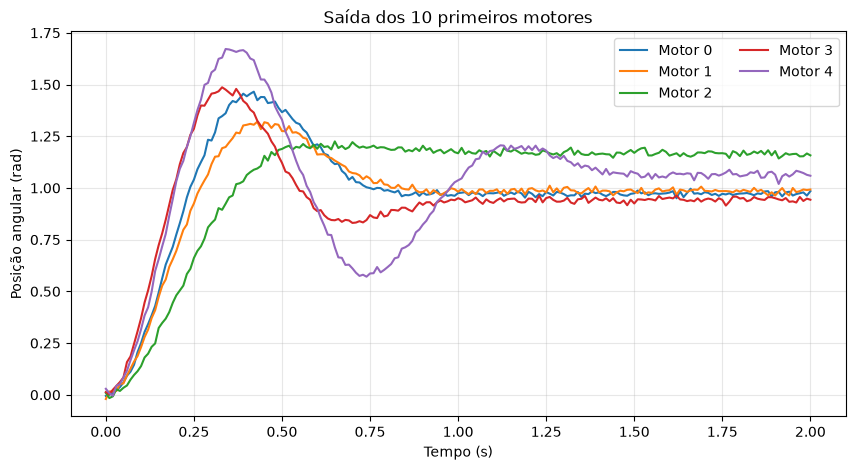

Shapes dos vetores e matrizes gerados:
t_eval: (1, 201)
r_input: (1, 201)
B_arr: (10000, 1)
K_arr: (10000, 1)
Tatrito_arr: (10000, 1)
delta_arr: (10000, 1)
Y_labels: (10000, 4)
state_0: (2, 1)
X_features: (10000, 201)
sol.t: (201,)
sol.y: (2, 201)


In [19]:
# Visualização dos 10 primeiros motores e diagnóstico dos shapes
r_input = np.ones_like(t_eval)

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(5):
    ax.plot(t_eval[0, :], X_features[i, :], label=f"Motor {i}", linewidth=1.5)

ax.set_title("Saída dos 10 primeiros motores")
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Posição angular (rad)")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
plt.show()

print("Shapes dos vetores e matrizes gerados:")
shapes = {
    "t_eval": t_eval.shape,
    "r_input": r_input.shape,
    "B_arr": B_arr.shape,
    "K_arr": K_arr.shape,
    "Tatrito_arr": Tatrito_arr.shape,
    "delta_arr": delta_arr.shape,
    "Y_labels": Y_labels.shape,
    "state_0": state_0.shape,
    "X_features": X_features.shape,
    "sol.t": sol.t.shape,
    "sol.y": sol.y.shape,
}
for name, shape in shapes.items():
    print(f"{name}: {shape}")

In [20]:
# Exportação do banco de dados para treinamento da MLP
feature_names = [f"feature_{i:03d}" for i in range(n_amostras)]
label_names = ["B", "K", "Tatrito", "delta"]
column_names = feature_names + label_names

dataset_mlp = np.hstack((X_features, Y_labels))

# Arquivo completo: features de entrada seguidas pelas labels de saída
np.savetxt(
    "database_mlp.csv",
    dataset_mlp,
    delimiter=",",
    header=",".join(column_names),
    comments="",
)

# Arquivos separados, caso a MLP seja treinada com X e Y em etapas diferentes
np.savetxt(
    "X_features.csv",
    X_features,
    delimiter=",",
    header=",".join(feature_names),
    comments="",
)
np.savetxt(
    "Y_labels.csv",
    Y_labels,
    delimiter=",",
    header=",".join(label_names),
    comments="",
)

print("Arquivos CSV exportados com sucesso:")
print("- database_mlp.csv:", dataset_mlp.shape)
print("- X_features.csv:", X_features.shape)
print("- Y_labels.csv:", Y_labels.shape)

Arquivos CSV exportados com sucesso:
- database_mlp.csv: (10000, 205)
- X_features.csv: (10000, 201)
- Y_labels.csv: (10000, 4)
